## 1) Environment และ Reproducibility

กำหนด random seed, data path และ import เครื่องมือที่ใช้ โมเดลใช้ `XGBRegressor` และ evaluation ทุกส่วนจะเรียงตามเวลา


In [1]:
"""XGBoost time-series forecast for USD/EUR.

The evaluation is chronological and compares 80/20 with 70/15/15 splits.
All model features are derived only from observations before each target date.
"""

from itertools import product
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from xgboost import XGBRegressor
import xgboost as xgb


warnings.filterwarnings("ignore")

SEED = 42
CV_SPLITS = 3
DATA_PATH = Path(
    r"C:\Users\User\Desktop\vs_nine\Project_stat\USD_EUR Historical Data.csv"
)


def show_table(table):
    """Use rich notebook display when available and plain print otherwise."""
    try:
        from IPython.display import display

        display(table)
    except ImportError:
        print(table.to_string())

## 2) ตรวจและ Clean ข้อมูล

- เก็บข้อมูลดิบไว้ก่อนแก้ไข
- แปลงวันที่และราคาเป็นชนิดที่ถูกต้อง
- ลบเฉพาะวันที่/ราคาที่อ่านไม่ได้และวันที่ซ้ำ
- เรียงข้อมูลจากอดีตไปอนาคต
- ไม่เติมวันหยุดตลาดและไม่ลบ price spikes อัตโนมัติ
- ไม่ใช้ `Vol.` เพราะ missing เป็นสัดส่วนสูง


In [2]:
def load_and_clean_data(path):
    raw_df = pd.read_csv(path)
    df = raw_df.copy()
    df["Date"] = pd.to_datetime(
        df["Date"],
        format="%m/%d/%Y",
        errors="coerce",
    )

    numeric_columns = ["Price", "Open", "High", "Low"]
    for column in numeric_columns:
        df[column] = pd.to_numeric(
            df[column].astype(str).str.replace(",", "", regex=False),
            errors="coerce",
        )

    quality = pd.Series(
        {
            "raw_rows": len(raw_df),
            "invalid_dates": int(df["Date"].isna().sum()),
            "invalid_prices": int(df["Price"].isna().sum()),
            "duplicate_dates": int(df["Date"].duplicated().sum()),
            "volume_missing_pct": round(df["Vol."].isna().mean() * 100, 2),
        },
        name="value",
    )

    df = (
        df.dropna(subset=["Date", "Price"])
        .drop_duplicates(subset=["Date"], keep="last")
        .sort_values("Date")
        .set_index("Date")
    )
    market_df = df[["Price", "Open", "High", "Low"]].copy()
    market_df[["Open", "High", "Low"]] = market_df[
        ["Open", "High", "Low"]
    ].ffill()
    return raw_df, market_df, quality

### ตรวจแนวโน้มราคาและ Log Return

กราฟใช้ตรวจ regime, trend และช่วงความผันผวน ไม่ใช้ข้อมูลจากกราฟในการปรับ Test set


In [3]:
def plot_clean_data(market_df):
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    axes[0].plot(market_df.index, market_df["Price"], color="navy")
    axes[0].set_title("USD/EUR price after cleaning")
    axes[0].set_ylabel("Price")
    axes[0].grid(alpha=0.25)

    log_return = np.log(market_df["Price"]).diff() * 100
    axes[1].plot(market_df.index, log_return, color="darkorange")
    axes[1].axhline(0, color="black", linewidth=0.8)
    axes[1].set_title("Daily log return")
    axes[1].set_ylabel("Percent")
    axes[1].grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## 3) Target และ Feature Engineering

Target คือ `Price` ณ observation ปัจจุบัน ส่วน feature ทุกตัวต้องทราบได้ก่อน target ได้แก่ price lags, lagged return, rolling mean/std, momentum, previous High–Low range, previous Open–Close change และ calendar fields

Rolling features เริ่มจาก `Price.shift(1)` จึงไม่เห็น target ปัจจุบันและไม่เกิด target leakage


In [4]:
def build_feature_frame(source_df, lookback):
    """Build target and strictly backward-looking predictors."""
    features = pd.DataFrame(index=source_df.index)
    features["target"] = source_df["Price"]

    for lag in range(1, lookback + 1):
        features[f"lag_{lag}"] = source_df["Price"].shift(lag)

    previous_price = source_df["Price"].shift(1)
    features["return_lag_1"] = (
        source_df["Price"].pct_change(fill_method=None).shift(1)
    )
    features["rolling_mean_5"] = previous_price.rolling(5).mean()
    features["rolling_mean_10"] = previous_price.rolling(10).mean()
    features["rolling_std_5"] = previous_price.rolling(5).std()
    features["rolling_std_10"] = previous_price.rolling(10).std()
    features["momentum_5"] = previous_price / source_df["Price"].shift(6) - 1
    features["range_lag_1"] = (
        source_df["High"] - source_df["Low"]
    ).shift(1)
    features["open_close_lag_1"] = (
        source_df["Price"] - source_df["Open"]
    ).shift(1)
    features["day_of_week"] = features.index.dayofweek
    features["month"] = features.index.month

    feature_columns = [
        column for column in features.columns if column != "target"
    ]
    return features, feature_columns

## 4) Metrics และ XGBoost Configuration

รายงาน MAE, RMSE, MAPE, sMAPE และ Directional Accuracy โดย XGBoost ไม่ต้อง scaling เพราะเป็น tree-based model

Hyperparameter grid ทดลอง lookback, `n_estimators`, `max_depth` และ `learning_rate`; ส่วน subsampling และ regularization ใช้ค่าคงที่แบบอนุรักษ์นิยม


In [5]:
def calculate_metrics(actual, predicted, previous_actual=None):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)
    error = actual - predicted

    nonzero = np.abs(actual) > 1e-12
    denominator = np.abs(actual) + np.abs(predicted)
    smape_mask = denominator > 1e-12
    result = {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": np.mean(
            np.abs(error[nonzero] / actual[nonzero])
        )
        * 100,
        "sMAPE (%)": np.mean(
            2 * np.abs(error[smape_mask]) / denominator[smape_mask]
        )
        * 100,
    }

    if previous_actual is not None:
        previous_actual = np.asarray(previous_actual, dtype=float).reshape(-1)
        actual_direction = np.sign(actual - previous_actual)
        predicted_direction = np.sign(predicted - previous_actual)
        result["Directional accuracy (%)"] = np.mean(
            actual_direction == predicted_direction
        ) * 100
    return result


def make_model(config):
    return XGBRegressor(
        objective="reg:squarederror",
        eval_metric="rmse",
        n_estimators=int(config["n_estimators"]),
        max_depth=int(config["max_depth"]),
        learning_rate=float(config["learning_rate"]),
        min_child_weight=3,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.01,
        reg_lambda=1.0,
        tree_method="hist",
        random_state=SEED,
        n_jobs=-1,
        verbosity=0,
    )


XGB_CONFIGS = [
    {
        "lookback": lookback,
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "learning_rate": learning_rate,
    }
    for lookback, n_estimators, max_depth, learning_rate in product(
        [5, 10, 20, 30],
        [200, 400],
        [2, 3],
        [0.03, 0.08],
    )
]

## 5) Expanding-window Cross-validation

ใช้ 3-fold `TimeSeriesSplit` ภายใน training partition เท่านั้น ลำดับทุก fold คือ `past train → later validation` และเลือกจากค่าเฉลี่ย validation RMSE


In [6]:
def run_xgb_time_series_cv(
    source_df,
    training_end_date,
    strategy,
    n_splits=CV_SPLITS,
):
    rows = []
    for config_id, config in enumerate(XGB_CONFIGS):
        feature_frame, feature_columns = build_feature_frame(
            source_df,
            config["lookback"],
        )
        training_data = feature_frame.loc[
            feature_frame.index < training_end_date
        ].dropna()
        splitter = TimeSeriesSplit(n_splits=n_splits)

        for fold, (train_index, validation_index) in enumerate(
            splitter.split(training_data),
            start=1,
        ):
            fold_train = training_data.iloc[train_index]
            fold_validation = training_data.iloc[validation_index]
            model = make_model(config)
            model.fit(
                fold_train[feature_columns],
                fold_train["target"],
            )
            train_prediction = model.predict(fold_train[feature_columns])
            validation_prediction = model.predict(
                fold_validation[feature_columns]
            )
            rows.append(
                {
                    "Strategy": strategy,
                    "config_id": config_id,
                    "fold": fold,
                    **config,
                    "train_RMSE": np.sqrt(
                        mean_squared_error(
                            fold_train["target"],
                            train_prediction,
                        )
                    ),
                    "validation_RMSE": np.sqrt(
                        mean_squared_error(
                            fold_validation["target"],
                            validation_prediction,
                        )
                    ),
                    "train_end": fold_train.index.max(),
                    "validation_start": fold_validation.index.min(),
                    "validation_end": fold_validation.index.max(),
                }
            )
    return pd.DataFrame(rows)


def summarize_cv(cv_results):
    group_columns = [
        "Strategy",
        "config_id",
        "lookback",
        "n_estimators",
        "max_depth",
        "learning_rate",
    ]
    return (
        cv_results.groupby(group_columns, as_index=False)
        .agg(
            mean_train_RMSE=("train_RMSE", "mean"),
            mean_RMSE=("validation_RMSE", "mean"),
            std_RMSE=("validation_RMSE", "std"),
        )
        .sort_values(["Strategy", "mean_RMSE"])
        .reset_index(drop=True)
    )


def config_from_row(row):
    return {
        "lookback": int(row["lookback"]),
        "n_estimators": int(row["n_estimators"]),
        "max_depth": int(row["max_depth"]),
        "learning_rate": float(row["learning_rate"]),
    }

## 6) เลือก Configuration โดยไม่แตะ Test

- 80/20 เลือก configuration ที่ CV mean RMSE ต่ำที่สุด
- 70/15/15 นำ 5 configuration แรกจาก CV ไปวัดบน Validation 15% แล้วเลือก validation RMSE ต่ำที่สุด
- Test ถูกล็อกไว้จนกว่าจะเลือก configuration เสร็จ


In [7]:
def select_config_with_validation(
    source_df,
    cv_summary,
    validation_start,
    test_start,
    shortlist_size=5,
):
    validation_candidates = []
    top_cv = cv_summary.sort_values("mean_RMSE").head(shortlist_size)

    for _, candidate_row in top_cv.iterrows():
        config = config_from_row(candidate_row)
        feature_frame, feature_columns = build_feature_frame(
            source_df,
            config["lookback"],
        )
        train_data = feature_frame.loc[
            feature_frame.index < validation_start
        ].dropna()
        validation_data = feature_frame.loc[
            (feature_frame.index >= validation_start)
            & (feature_frame.index < test_start)
        ].dropna()

        model = make_model(config)
        model.fit(train_data[feature_columns], train_data["target"])
        train_prediction = model.predict(train_data[feature_columns])
        validation_prediction = model.predict(
            validation_data[feature_columns]
        )
        validation_candidates.append(
            {
                **config,
                "CV mean RMSE": candidate_row["mean_RMSE"],
                "Train RMSE": np.sqrt(
                    mean_squared_error(
                        train_data["target"],
                        train_prediction,
                    )
                ),
                "Validation RMSE": np.sqrt(
                    mean_squared_error(
                        validation_data["target"],
                        validation_prediction,
                    )
                ),
            }
        )

    return (
        pd.DataFrame(validation_candidates)
        .sort_values("Validation RMSE")
        .reset_index(drop=True)
    )

## 7) Train, Locked Test และ Naive Baseline

Naive forecast ใช้ราคาจริงล่าสุดที่ทราบ (`lag_1`) เป็นค่าพยากรณ์ โมเดล XGBoost ควรมี error ต่ำกว่า baseline นี้จึงจะสร้างประโยชน์เพิ่ม


In [8]:
def fit_and_test(source_df, test_start_date, config):
    feature_frame, feature_columns = build_feature_frame(
        source_df,
        config["lookback"],
    )
    model_data = feature_frame.dropna()
    train_data = model_data.loc[model_data.index < test_start_date]
    test_data = model_data.loc[model_data.index >= test_start_date]

    model = make_model(config)
    model.fit(train_data[feature_columns], train_data["target"])
    train_prediction = model.predict(train_data[feature_columns])
    test_prediction = model.predict(test_data[feature_columns])

    return {
        "model": model,
        "feature_columns": feature_columns,
        "train_data": train_data,
        "test_data": test_data,
        "prediction": test_prediction,
        "naive_prediction": test_data["lag_1"].to_numpy(),
        "train_RMSE": np.sqrt(
            mean_squared_error(train_data["target"], train_prediction)
        ),
    }


def build_comparison(results):
    rows = []
    for strategy, result in results.items():
        actual = result["test_data"]["target"].to_numpy()
        previous_actual = result["test_data"]["lag_1"].to_numpy()
        xgb_metrics = calculate_metrics(
            actual,
            result["prediction"],
            previous_actual,
        )
        naive_metrics = calculate_metrics(
            actual,
            result["naive_prediction"],
            previous_actual,
        )
        improvement = (
            (naive_metrics["RMSE"] - xgb_metrics["RMSE"])
            / naive_metrics["RMSE"]
            * 100
        )
        common = {
            "Test start": result["test_data"].index.min().date(),
            "Test end": result["test_data"].index.max().date(),
            "Test observations": len(result["test_data"]),
        }
        rows.extend(
            [
                {
                    "Strategy": strategy,
                    "Model": "XGBoost",
                    **xgb_metrics,
                    "RMSE better than naive (%)": improvement,
                    **common,
                },
                {
                    "Strategy": strategy,
                    "Model": "Naive",
                    **naive_metrics,
                    "RMSE better than naive (%)": 0.0,
                    **common,
                },
            ]
        )
    return pd.DataFrame(rows)

### กราฟ Actual, XGBoost และ Naive

แสดงผลแยกตาม split เพราะ 80/20 และ 70/15/15 มีช่วง Test ไม่เหมือนกัน


In [9]:
def plot_test_forecasts(results, comparison):
    fig, axes = plt.subplots(2, 1, figsize=(14, 10))
    for ax, (strategy, result) in zip(axes, results.items()):
        dates = result["test_data"].index
        ax.plot(
            dates,
            result["test_data"]["target"],
            label="Actual",
            color="navy",
        )
        ax.plot(
            dates,
            result["prediction"],
            label="XGBoost",
            color="crimson",
            alpha=0.85,
        )
        ax.plot(
            dates,
            result["naive_prediction"],
            label="Naive",
            color="gray",
            alpha=0.65,
        )
        ax.set_title(f"{strategy} locked-test forecast")
        ax.set_ylabel("USD/EUR")
        ax.legend()
        ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    # เปรียบเทียบ forecast ของทั้งสอง split บนช่วง Test ที่มีวันที่ตรงกัน
    result_80 = results["80/20"]
    result_70 = results["70/15/15"]
    forecast_80_series = pd.Series(
        result_80["prediction"],
        index=result_80["test_data"].index,
        name="XGBoost 80/20",
    )
    forecast_70_series = pd.Series(
        result_70["prediction"],
        index=result_70["test_data"].index,
        name="XGBoost 70/15/15",
    )
    common_forecast_comparison = pd.concat(
        [
            result_80["test_data"]["target"].rename(
                "Actual closing price"
            ),
            forecast_80_series,
            forecast_70_series,
        ],
        axis=1,
        join="inner",
    ).dropna()

    plt.figure(figsize=(14, 6))
    plt.plot(
        common_forecast_comparison.index,
        common_forecast_comparison["Actual closing price"],
        label="Actual closing price",
        color="black",
        linewidth=2.2,
    )
    plt.plot(
        common_forecast_comparison.index,
        common_forecast_comparison["XGBoost 80/20"],
        label="XGBoost 80/20",
        color="#2563eb",
        linewidth=1.5,
        linestyle="--",
    )
    plt.plot(
        common_forecast_comparison.index,
        common_forecast_comparison["XGBoost 70/15/15"],
        label="XGBoost 70/15/15",
        color="#f97316",
        linewidth=1.5,
        linestyle=":",
    )
    plt.title("Actual vs XGBoost Forecasts on the Common Test Period")
    plt.xlabel("Date")
    plt.ylabel("USD/EUR closing price")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(
        "Common test period:",
        common_forecast_comparison.index.min().date(),
        "to",
        common_forecast_comparison.index.max().date(),
    )

    error_plot = (
        comparison.loc[comparison["Model"] == "XGBoost"]
        .set_index("Strategy")[["MAPE (%)", "sMAPE (%)"]]
    )
    ax = error_plot.plot(kind="bar", figsize=(9, 5), rot=0)
    ax.set_title("XGBoost percentage error by strategy")
    ax.set_ylabel("Percent")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

## 8) Residual Diagnostics

XGBoost ไม่บังคับ stationarity หรือ residual normality แบบ ARIMA แต่ควรตรวจ overfitting, residual mean bias และ residual autocorrelation ส่วน Jarque–Bera และ ARCH เป็น diagnostics เพิ่มเติมเกี่ยวกับ distribution และ volatility


In [10]:
def xgb_diagnostics(strategy, result, overfit_ratio):
    residuals = (
        result["test_data"]["target"].to_numpy()
        - result["prediction"]
    )
    diagnostic_lag = min(10, max(1, len(residuals) // 5))
    bias_test = stats.ttest_1samp(residuals, popmean=0.0)
    ljung_box = acorr_ljungbox(
        residuals,
        lags=[diagnostic_lag],
        return_df=True,
    ).iloc[0]
    jarque_bera = stats.jarque_bera(residuals)
    _, arch_pvalue, _, _ = het_arch(
        residuals,
        nlags=diagnostic_lag,
    )
    return (
        {
            "Strategy": strategy,
            "Overfit ratio": overfit_ratio,
            "Overfit heuristic pass": overfit_ratio <= 1.5,
            "Residual mean": residuals.mean(),
            "Bias p-value": bias_test.pvalue,
            "No mean bias pass": bias_test.pvalue > 0.05,
            f"Ljung-Box p-value (lag {diagnostic_lag})": ljung_box[
                "lb_pvalue"
            ],
            "Residual independence pass": ljung_box["lb_pvalue"] > 0.05,
            "Jarque-Bera p-value": jarque_bera.pvalue,
            "ARCH p-value": arch_pvalue,
        },
        residuals,
    )

### Residual Plots และ Feature Importance

Residual ที่ดีควรกระจายรอบศูนย์และไม่มี pattern ตามเวลา ส่วน feature importance ช่วยอธิบายว่าโมเดลพึ่งพาตัวแปรใดมากที่สุด


In [11]:
def plot_diagnostics(results, residual_sets):
    fig, axes = plt.subplots(2, 3, figsize=(17, 8))
    for row, ((strategy, result), residuals) in enumerate(
        zip(results.items(), residual_sets)
    ):
        axes[row, 0].plot(
            result["test_data"].index,
            residuals,
            color="teal",
        )
        axes[row, 0].axhline(0, color="black", linewidth=0.8)
        axes[row, 0].set_title(f"{strategy}: residual over time")
        axes[row, 0].grid(alpha=0.25)
        axes[row, 1].hist(
            residuals,
            bins=25,
            color="slateblue",
            alpha=0.8,
        )
        axes[row, 1].set_title(f"{strategy}: residual distribution")
        stats.probplot(residuals, dist="norm", plot=axes[row, 2])
        axes[row, 2].set_title(f"{strategy}: Q-Q plot")
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, (strategy, result) in zip(axes, results.items()):
        importance = pd.Series(
            result["model"].feature_importances_,
            index=result["feature_columns"],
        ).sort_values(ascending=False).head(15).sort_values()
        importance.plot(kind="barh", ax=ax, color="forestgreen")
        ax.set_title(f"{strategy}: top feature importance")
        ax.set_xlabel("Gain-based importance")
    plt.tight_layout()
    plt.show()

## 9) Final Model และ Next-observation Forecast

หลังประเมินเสร็จจะ fit โมเดลใหม่ด้วยข้อมูลทั้งหมด วันที่ forecast ใช้วันทำการถัดไปเป็นตัวแทนและอาจไม่ตรงวันเปิดตลาดจริงหากมีวันหยุดพิเศษ


In [12]:
def fit_all_and_forecast_next(source_df, config):
    next_date = source_df.index.max() + pd.offsets.BDay(1)
    future_row = pd.DataFrame(
        {
            "Price": [np.nan],
            "Open": [np.nan],
            "High": [np.nan],
            "Low": [np.nan],
        },
        index=[next_date],
    )
    extended_df = pd.concat([source_df, future_row])
    feature_frame, feature_columns = build_feature_frame(
        extended_df,
        config["lookback"],
    )
    training_data = feature_frame.iloc[:-1].dropna()
    next_features = feature_frame.loc[[next_date], feature_columns]
    if next_features.isna().any(axis=None):
        raise ValueError("Next-observation features contain missing values")

    final_model = make_model(config)
    final_model.fit(
        training_data[feature_columns],
        training_data["target"],
    )
    forecast = float(final_model.predict(next_features)[0])
    return final_model, next_date, forecast

## 10) รัน Workflow และสรุปผล

เซลล์ถัดไปเรียกฟังก์ชันทั้งหมดตามลำดับ แสดง data quality, split, CV results, locked-test metrics, diagnostics, feature importance และ final forecast


In [13]:
def run_workflow():
    np.random.seed(SEED)
    print("XGBoost version:", xgb.__version__)
    print("Data path:", DATA_PATH)

    raw_df, market_df, quality = load_and_clean_data(DATA_PATH)
    show_table(quality.to_frame())
    show_table(market_df.head())
    show_table(market_df.tail())
    print(f"Clean rows: {len(market_df):,}")
    print(
        f"Period: {market_df.index.min().date()} "
        f"to {market_df.index.max().date()}"
    )
    plot_clean_data(market_df)

    example_features, example_columns = build_feature_frame(
        market_df,
        lookback=10,
    )
    print("Feature example (strictly backward-looking):")
    show_table(example_features.dropna().head())
    print("Feature count for lookback=10:", len(example_columns))

    n = len(market_df)
    split_80_position = int(n * 0.80)
    split_70_position = int(n * 0.70)
    split_85_position = int(n * 0.85)
    test_start_20 = market_df.index[split_80_position]
    validation_start_15 = market_df.index[split_70_position]
    test_start_15 = market_df.index[split_85_position]

    split_summary = pd.DataFrame(
        [
            {
                "Strategy": "80/20",
                "Train end": market_df.index[split_80_position - 1].date(),
                "Validation": "CV inside train",
                "Test start": test_start_20.date(),
                "Test end": market_df.index.max().date(),
                "Raw train rows": split_80_position,
                "Raw test rows": n - split_80_position,
            },
            {
                "Strategy": "70/15/15",
                "Train end": market_df.index[split_70_position - 1].date(),
                "Validation": (
                    f"{validation_start_15.date()} to "
                    f"{market_df.index[split_85_position - 1].date()}"
                ),
                "Test start": test_start_15.date(),
                "Test end": market_df.index.max().date(),
                "Raw train rows": split_70_position,
                "Raw test rows": n - split_85_position,
            },
        ]
    )
    print("Chronological split summary:")
    show_table(split_summary)

    print(f"Testing {len(XGB_CONFIGS)} configurations per strategy...")
    print("Running XGBoost CV for train 80%...")
    cv_results_80 = run_xgb_time_series_cv(
        market_df,
        test_start_20,
        "80/20",
    )
    print("Running XGBoost CV for train 70%...")
    cv_results_70 = run_xgb_time_series_cv(
        market_df,
        validation_start_15,
        "70/15/15",
    )
    cv_results = pd.concat(
        [cv_results_80, cv_results_70],
        ignore_index=True,
    )
    cv_summary = summarize_cv(cv_results)
    show_table(
        cv_summary.groupby("Strategy", group_keys=False).head(10)
    )

    best_row_80 = (
        cv_summary.loc[cv_summary["Strategy"] == "80/20"]
        .sort_values("mean_RMSE")
        .iloc[0]
    )
    best_config_80 = config_from_row(best_row_80)
    summary_70 = cv_summary.loc[
        cv_summary["Strategy"] == "70/15/15"
    ]
    validation_selection_70 = select_config_with_validation(
        market_df,
        summary_70,
        validation_start_15,
        test_start_15,
    )
    best_validation_70 = validation_selection_70.iloc[0]
    best_config_70 = config_from_row(best_validation_70)
    print("Best 80/20 config from CV:", best_config_80)
    print(
        "Best 70/15/15 config from CV shortlist + validation:",
        best_config_70,
    )
    show_table(validation_selection_70)

    result_80 = fit_and_test(market_df, test_start_20, best_config_80)
    result_70 = fit_and_test(market_df, test_start_15, best_config_70)
    results = {"80/20": result_80, "70/15/15": result_70}
    comparison = build_comparison(results)
    print("Locked-test comparison:")
    show_table(comparison.round(6))
    plot_test_forecasts(results, comparison)

    overfit_ratio_80 = (
        best_row_80["mean_RMSE"] / best_row_80["mean_train_RMSE"]
    )
    overfit_ratio_70 = (
        best_validation_70["Validation RMSE"]
        / best_validation_70["Train RMSE"]
    )
    diagnostic_80, residuals_80 = xgb_diagnostics(
        "80/20",
        result_80,
        overfit_ratio_80,
    )
    diagnostic_70, residuals_70 = xgb_diagnostics(
        "70/15/15",
        result_70,
        overfit_ratio_70,
    )
    diagnostics = pd.DataFrame([diagnostic_80, diagnostic_70])
    print("Diagnostics:")
    show_table(diagnostics.round(6))
    plot_diagnostics(results, [residuals_80, residuals_70])

    final_model_80, next_date_80, forecast_80 = (
        fit_all_and_forecast_next(market_df, best_config_80)
    )
    final_model_70, next_date_70, forecast_70 = (
        fit_all_and_forecast_next(market_df, best_config_70)
    )
    final_forecasts = pd.DataFrame(
        [
            {
                "Strategy source": "80/20 CV winner",
                "Last observed date": market_df.index.max().date(),
                "Forecast date proxy": next_date_80.date(),
                "Last actual price": market_df["Price"].iloc[-1],
                "Forecast price": forecast_80,
                **best_config_80,
            },
            {
                "Strategy source": "70/15/15 validation winner",
                "Last observed date": market_df.index.max().date(),
                "Forecast date proxy": next_date_70.date(),
                "Last actual price": market_df["Price"].iloc[-1],
                "Forecast price": forecast_70,
                **best_config_70,
            },
        ]
    )
    print("Final next-observation forecasts:")
    show_table(final_forecasts.round(6))

    xgb_rows = comparison.loc[comparison["Model"] == "XGBoost"]
    best_test_row = xgb_rows.sort_values("MAPE (%)").iloc[0]
    print("=" * 72)
    print("XGBOOST EVALUATION SUMMARY")
    print("=" * 72)
    print(f"Lowest test MAPE strategy: {best_test_row['Strategy']}")
    print(f"Test MAPE: {best_test_row['MAPE (%)']:.4f}%")
    print(f"Test RMSE: {best_test_row['RMSE']:.6f}")
    print(
        "RMSE better than naive: "
        f"{best_test_row['RMSE better than naive (%)']:.2f}%"
    )
    print(
        "Directional accuracy: "
        f"{best_test_row['Directional accuracy (%)']:.2f}%"
    )
    if best_test_row["RMSE better than naive (%)"] > 0:
        print("Conclusion: XGBoost beats the naive baseline on this test period.")
    else:
        print(
            "Conclusion: XGBoost does not beat the naive baseline; "
            "do not promote this model to production."
        )
    if not diagnostics[
        ["Overfit heuristic pass", "No mean bias pass", "Residual independence pass"]
    ].all(axis=None):
        print(
            "Diagnostics warning: at least one split shows overfitting, "
            "residual bias, or residual autocorrelation."
        )
    print("The two strategies use different locked-test periods.")
    print("Final forecast is a model estimate, not trading advice.")

    return {
        "raw_df": raw_df,
        "market_df": market_df,
        "split_summary": split_summary,
        "cv_results": cv_results,
        "cv_summary": cv_summary,
        "best_config_80": best_config_80,
        "best_config_70": best_config_70,
        "validation_selection_70": validation_selection_70,
        "results": results,
        "comparison": comparison,
        "diagnostics": diagnostics,
        "final_forecasts": final_forecasts,
        "final_model_80": final_model_80,
        "final_model_70": final_model_70,
    }

XGBoost version: 3.2.0
Data path: C:\Users\User\Desktop\vs_nine\Project_stat\USD_EUR Historical Data.csv


,value
raw_rows,1044.00
invalid_dates,0.00
invalid_prices,0.00
duplicate_dates,0.00
volume_missing_pct,85.73


,Price,Open,High,Low
Date,,,,
2022-07-01,0.9589,0.9541,0.9647,0.9536
2022-07-04,0.9594,0.9593,0.9601,0.9557
2022-07-05,0.9739,0.9598,0.9771,0.9570
2022-07-06,0.9822,0.9739,0.9842,0.9731
2022-07-07,0.9842,0.9822,0.9859,0.9783


,Price,Open,High,Low
Date,,,,
2026-06-25,0.8796,0.8802,0.8824,0.8781
2026-06-26,0.8784,0.8795,0.8808,0.8745
2026-06-29,0.8756,0.8779,0.8789,0.8748
2026-06-30,0.8756,0.8756,0.8786,0.8743
2026-07-01,0.8790,0.8756,0.8802,0.8752


Clean rows: 1,044
Period: 2022-07-01 to 2026-07-01


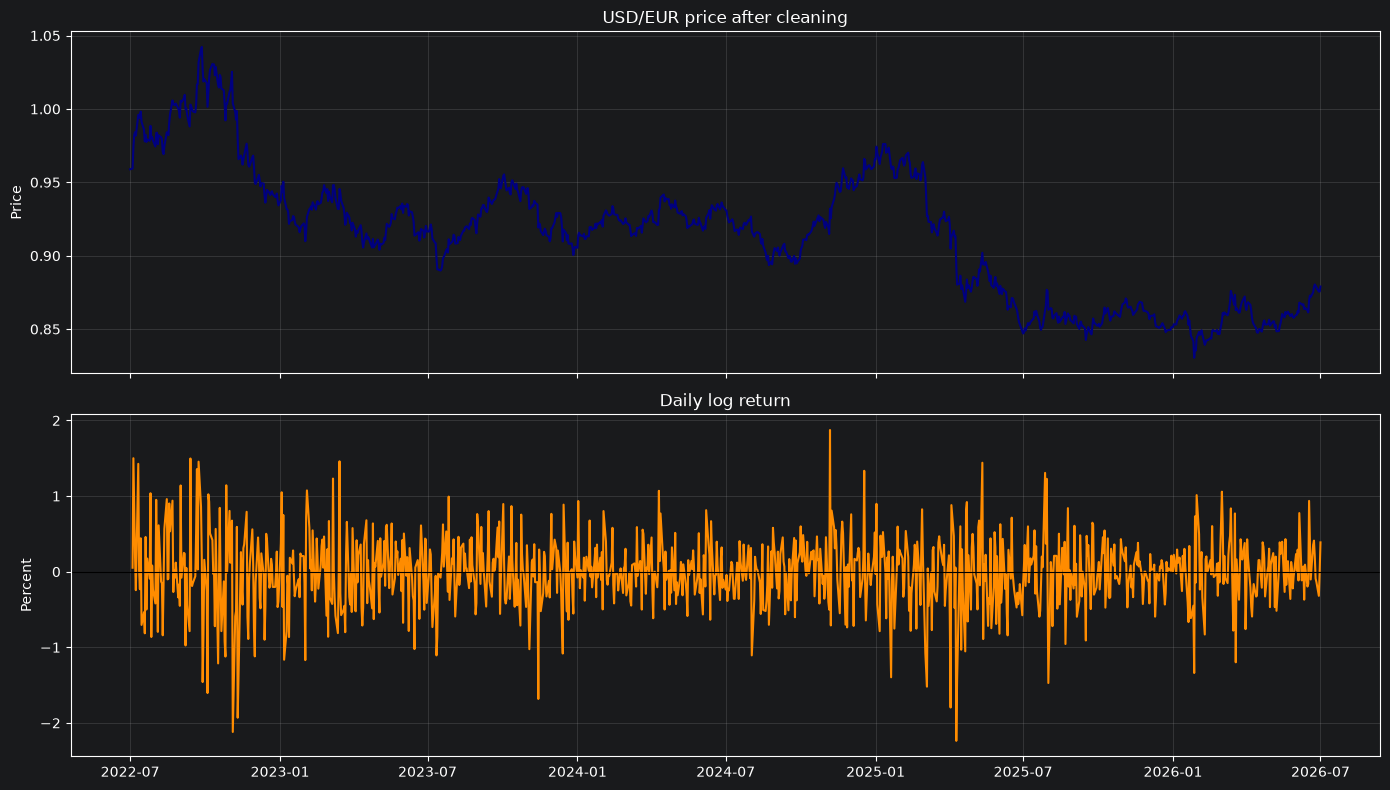

Feature example (strictly backward-looking):


,target,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,...,return_lag_1,rolling_mean_5,rolling_mean_10,rolling_std_5,rolling_std_10,momentum_5,range_lag_1,open_close_lag_1,day_of_week,month
Date,,,,,,,,,,,,,,,,,,,,,
2022-07-15,0.9912,0.9982,0.9938,0.9961,0.9959,0.9818,0.9842,0.9822,0.9739,0.9594,...,0.004427,0.99316,0.98244,0.006539,0.014555,0.014225,0.0113,0.0043,4,7
2022-07-18,0.9859,0.9912,0.9982,0.9938,0.9961,0.9959,0.9818,0.9842,0.9822,0.9739,...,-0.007013,0.99504,0.98567,0.002652,0.012133,0.009574,0.0091,-0.0070,0,7
2022-07-19,0.9779,0.9859,0.9912,0.9982,0.9938,0.9961,0.9959,0.9818,0.9842,0.9822,...,-0.005347,0.99304,0.98832,0.004768,0.007921,-0.010041,0.0121,-0.0057,1,7
2022-07-20,0.9824,0.9779,0.9859,0.9912,0.9982,0.9938,0.9961,0.9959,0.9818,0.9842,...,-0.008114,0.98940,0.98872,0.007819,0.007178,-0.018271,0.0144,-0.0081,2,7
2022-07-21,0.9775,0.9824,0.9779,0.9859,0.9912,0.9982,0.9938,0.9961,0.9959,0.9818,...,0.004602,0.98712,0.98874,0.007877,0.007158,-0.011471,0.0114,0.0045,3,7


Feature count for lookback=10: 20
Chronological split summary:


,Strategy,Train end,Validation,Test start,Test end,Raw train rows,Raw test rows
0,80/20,2025-09-11,CV inside train,2025-09-12,2026-07-01,835,209
1,70/15/15,2025-04-17,2025-04-18 to 2025-11-24,2025-11-25,2026-07-01,730,157


Testing 32 configurations per strategy...
Running XGBoost CV for train 80%...
Running XGBoost CV for train 70%...


,Strategy,config_id,lookback,n_estimators,max_depth,learning_rate,mean_train_RMSE,mean_RMSE,std_RMSE
0,70/15/15,28,30,400,2,0.03,0.003051,0.006096,0.002413
1,70/15/15,25,30,200,2,0.08,0.002710,0.006103,0.002251
2,70/15/15,24,30,200,2,0.03,0.003818,0.006257,0.002657
3,70/15/15,29,30,400,2,0.08,0.001992,0.006287,0.002281
4,70/15/15,5,5,400,2,0.08,0.002617,0.006337,0.002724
5,70/15/15,1,5,200,2,0.08,0.003293,0.006341,0.002857
6,70/15/15,4,5,400,2,0.03,0.003562,0.006367,0.002891
7,70/15/15,9,10,200,2,0.08,0.003190,0.006410,0.002904
8,70/15/15,6,5,400,3,0.03,0.002708,0.006462,0.002961
9,70/15/15,3,5,200,3,0.08,0.002382,0.006483,0.003036


Best 80/20 config from CV: {'lookback': 5, 'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.03}
Best 70/15/15 config from CV shortlist + validation: {'lookback': 30, 'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.08}


,lookback,n_estimators,max_depth,learning_rate,CV mean RMSE,Train RMSE,Validation RMSE
0,30,400,2,0.08,0.006287,0.002652,0.030700
1,30,200,2,0.08,0.006103,0.003313,0.030725
2,30,400,2,0.03,0.006096,0.003531,0.031401
3,30,200,2,0.03,0.006257,0.004045,0.031855
4,5,400,2,0.08,0.006337,0.003116,0.032224


Locked-test comparison:


,Strategy,Model,MAE,RMSE,MAPE (%),sMAPE (%),Directional accuracy (%),RMSE better than naive (%),Test start,Test end,Test observations
0,80/20,XGBoost,0.003984,0.005298,0.466566,0.465445,52.153110,-72.355964,2025-09-12,2026-07-01,209
1,80/20,Naive,0.002330,0.003074,0.271738,0.271736,3.827751,0.000000,2025-09-12,2026-07-01,209
2,70/15/15,XGBoost,0.003334,0.004757,0.390481,0.389567,61.146497,-49.924470,2025-11-25,2026-07-01,157
3,70/15/15,Naive,0.002355,0.003173,0.274790,0.274767,4.458599,0.000000,2025-11-25,2026-07-01,157


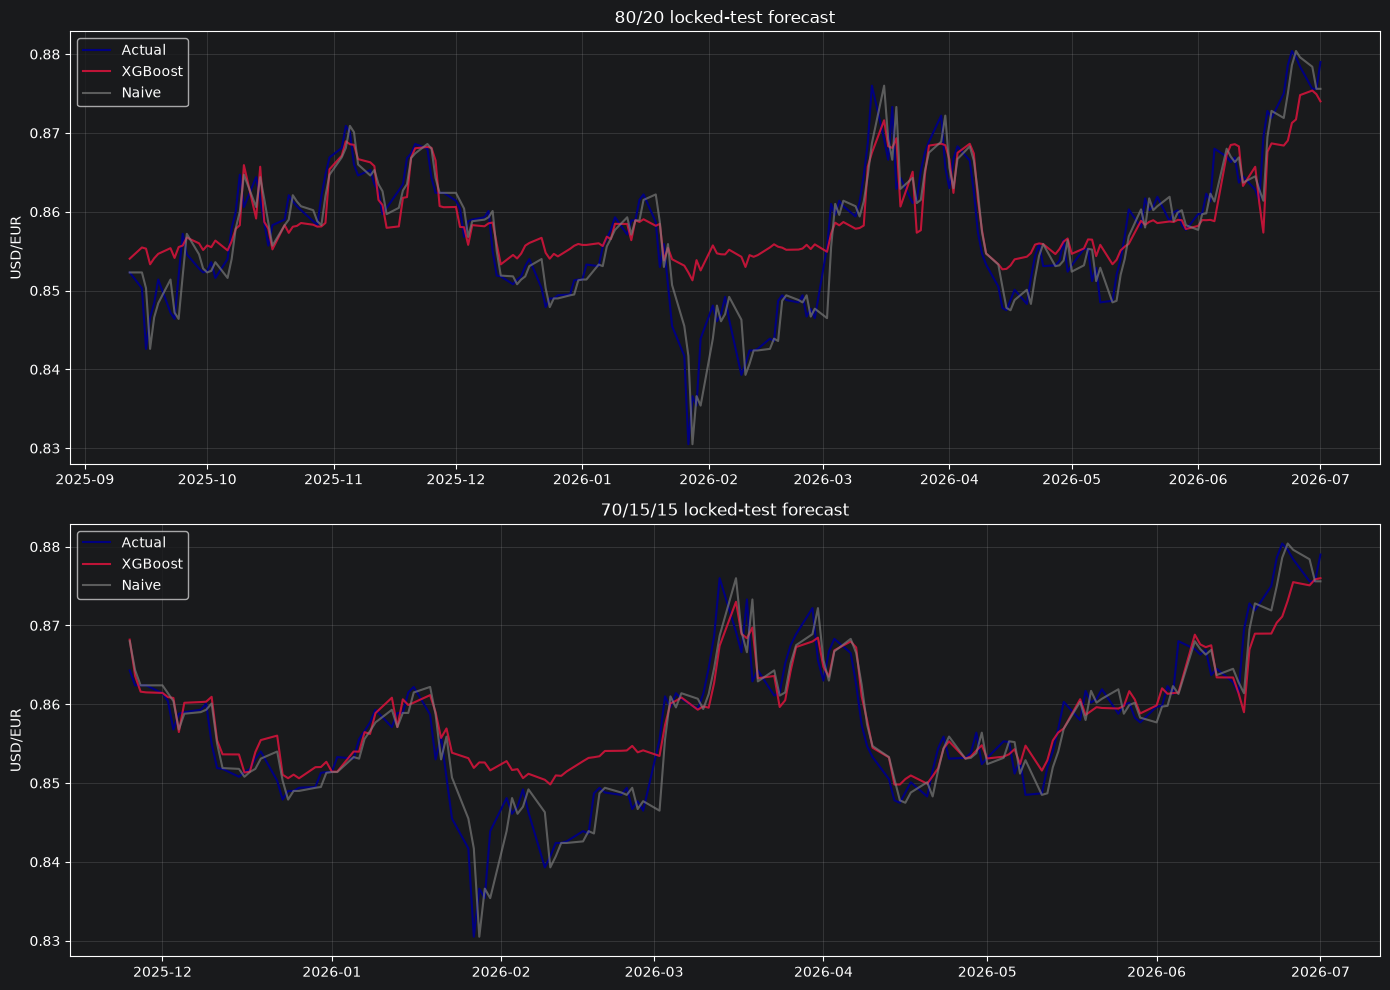

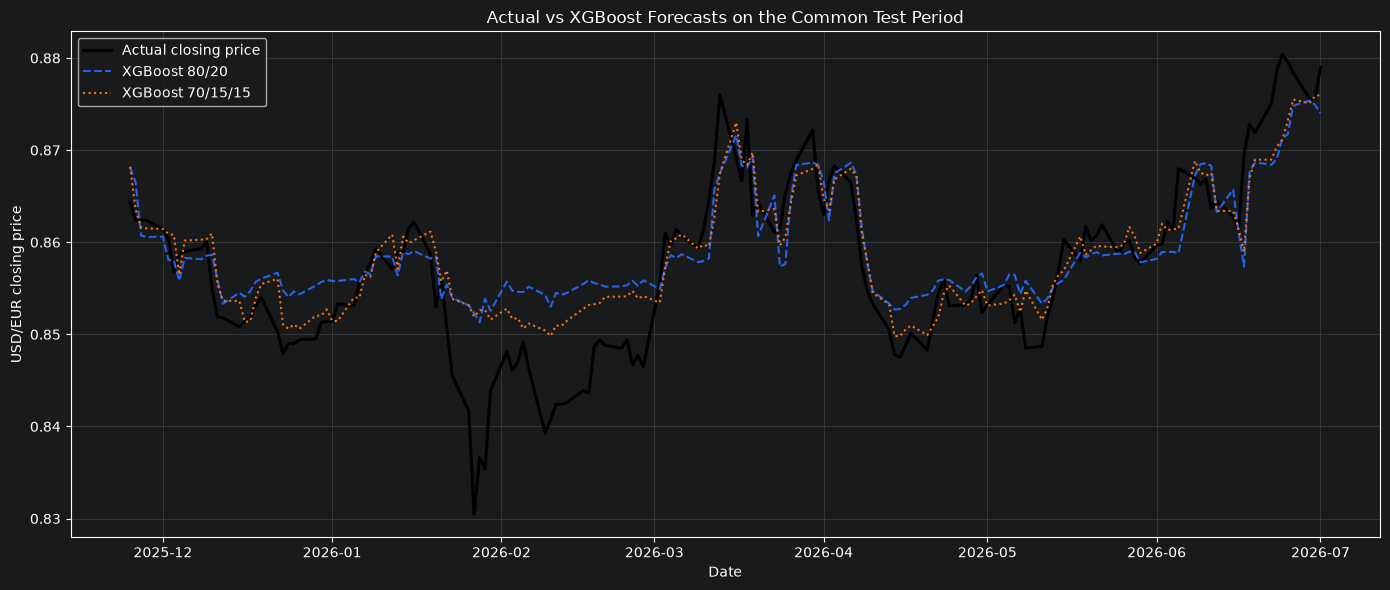

Common test period: 2025-11-25 to 2026-07-01


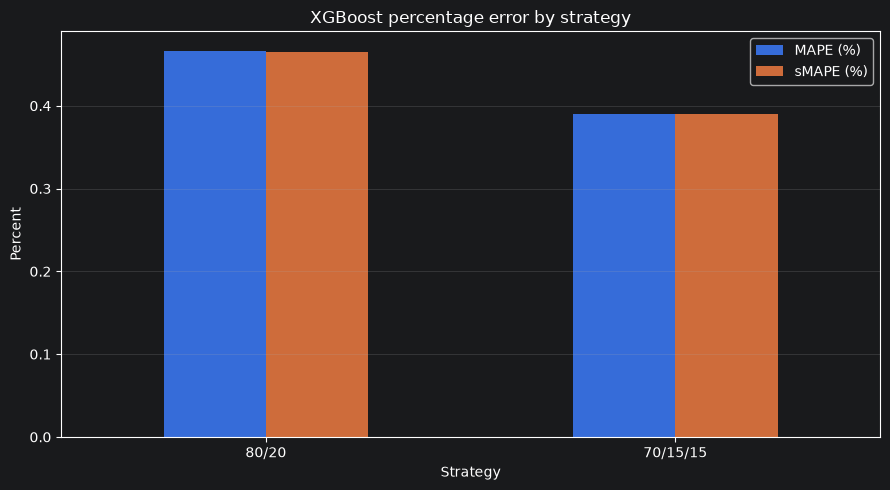

Diagnostics:


,Strategy,Overfit ratio,Overfit heuristic pass,Residual mean,Bias p-value,No mean bias pass,Ljung-Box p-value (lag 10),Residual independence pass,Jarque-Bera p-value,ARCH p-value
0,80/20,3.261926,False,-0.001519,0.000024,False,0.0,False,0.000001,0.0
1,70/15/15,11.578216,False,-0.001332,0.000368,False,0.0,False,0.000000,0.0


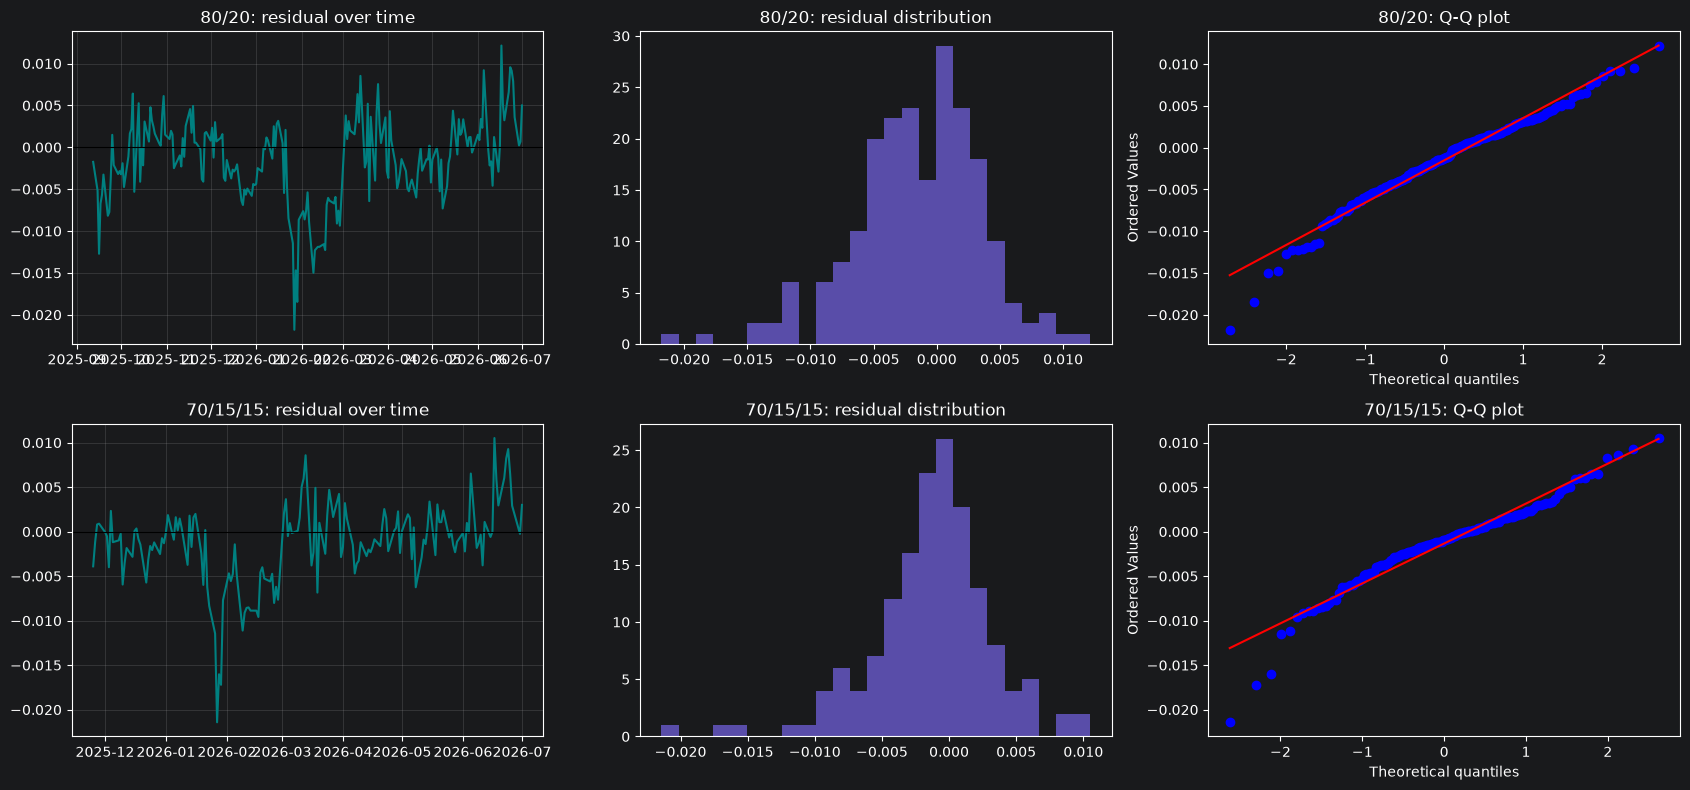

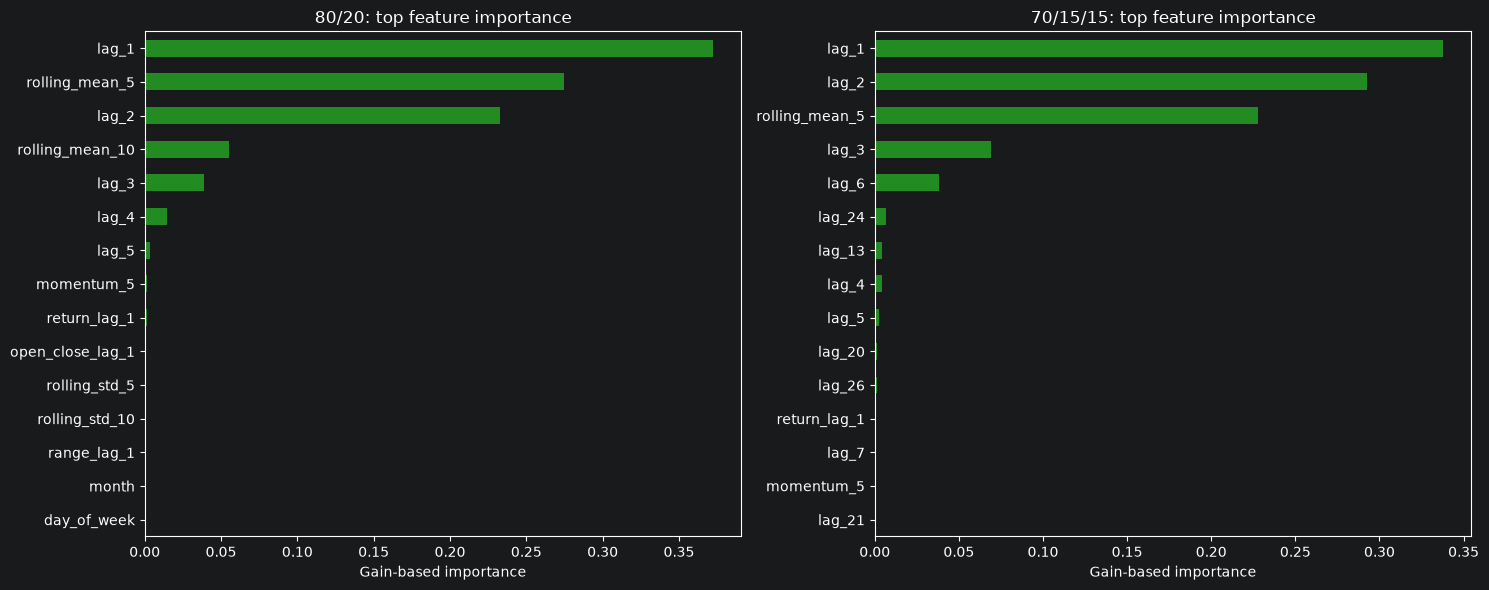

Final next-observation forecasts:


,Strategy source,Last observed date,Forecast date proxy,Last actual price,Forecast price,lookback,n_estimators,max_depth,learning_rate
0,80/20 CV winner,2026-07-01,2026-07-02,0.879,0.877589,5,400,2,0.03
1,70/15/15 validation winner,2026-07-01,2026-07-02,0.879,0.876480,30,400,2,0.08


XGBOOST EVALUATION SUMMARY
Lowest test MAPE strategy: 70/15/15
Test MAPE: 0.3905%
Test RMSE: 0.004757
RMSE better than naive: -49.92%
Directional accuracy: 61.15%
Conclusion: XGBoost does not beat the naive baseline; do not promote this model to production.
Diagnostics warning: at least one split shows overfitting, residual bias, or residual autocorrelation.
The two strategies use different locked-test periods.
Final forecast is a model estimate, not trading advice.


In [14]:
workflow_results = run_workflow()

## เกณฑ์การอ่านผล

1. MAE, RMSE, MAPE และ sMAPE บน Test ยิ่งต่ำยิ่งดี
2. `RMSE better than naive (%)` ต้องเป็นค่าบวกจึงจะชนะ naive baseline
3. Directional Accuracy สูงกว่า 50% สื่อว่าโมเดลจับทิศทางได้ดีกว่าการเดาสุ่มเชิงสัญญาณ
4. CV mean error ควรต่ำและ std ระหว่าง folds ไม่สูง
5. Overfit ratio ไม่ควรสูงผิดปกติ และ residual ไม่ควรมี mean bias/autocorrelation
6. ผล 80/20 กับ 70/15/15 ใช้ Test คนละช่วง จึงต้องอ่าน test period ร่วมกับ error
7. Forecast สุดท้ายเป็น point forecast และไม่ใช่คำแนะนำซื้อขาย
